# 07. Q5 어떤 개선 조치가 가장 큰 효과를 낼 것인가?

Q1~Q4 결과를 바탕으로 개선안별 **연간 1~2점 리뷰 감소 건수**를 추정하고 우선순위를 정한다.

- **기준 기간**: 데이터 수집 종료일(2018-08-29) 이전 12개월에 구매한 주문 중 리뷰가 있는 주문 (`sql/analysis/q5_01_order_base.sql`)
- **공통 틀**: 개선안마다 대상 주문을 정하고, 대상 주문 중 일정 비율(시나리오)을 "개선"한다. 개선된 주문은 1~2점 확률이 반사실 수준으로 내려간다.
  주문별 감소량 Δ를 더하면 연간 1~2점 감소 건수다. 무작위로 어떤 주문을 개선할지 고르는 과정을 500번 반복해 평균과 범위(2.5~97.5 백분위)를 낸다.
- **중복 제거**: 같은 주문이 여러 개선안의 대상이면 **가장 큰 감소 하나만 인정**한다(보수적).
- 결과 정리: `reports/analysis/q5_recommendations.md` / 차트: `reports/figures/q5_*.png`

**주의**: 관찰 데이터의 연관을 "개선하면 그만큼 줄어든다"로 옮긴 시나리오 추정이다. 인과 효과를 보장하지 않는다.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import display
from scipy.optimize import minimize
from scipy.stats import betabinom
from sqlalchemy import text


def find_project_root(start: Path) -> Path:
    """sql/analysis 폴더가 있는 프로젝트 루트를 찾는다."""
    for path in [start, *start.parents]:
        if (path / "sql" / "analysis").is_dir():
            return path
    raise FileNotFoundError("프로젝트 루트를 찾지 못함")


ROOT = find_project_root(Path.cwd())
SQL_DIR = ROOT / "sql" / "analysis"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "src" / "etl"))
from db import get_engine  # noqa: E402

engine = get_engine()
rng = np.random.default_rng(42)
N_REPS = 500

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

LABELS = ["NOT_RECEIVED", "WRONG_MISSING", "DAMAGED", "NOT_AS_DESCRIBED", "LOW_QUALITY", "SHIPPING_COST",
          "DELAY", "SERVICE", "OTHER", "UNCLEAR", "NO_COMPLAINT"]
LABEL_KO = {
    "NOT_RECEIVED": "미수령", "WRONG_MISSING": "오배송·누락", "DAMAGED": "파손·불량",
    "NOT_AS_DESCRIBED": "설명 불일치", "LOW_QUALITY": "품질 불만", "SHIPPING_COST": "배송비·수령 불편",
    "DELAY": "배송 지연", "SERVICE": "응대·환불", "OTHER": "기타", "UNCLEAR": "판단 불가", "NO_COMPLAINT": "불만 없음",
}
SELLER_TYPES = ["WRONG_MISSING", "DAMAGED", "NOT_AS_DESCRIBED", "LOW_QUALITY", "SERVICE"]
REPURCHASE_DIFF = 0.0044  # Q3: 첫 주문 1~2점 vs 4~5점의 180일 재구매율 차이(0.44%p)


def run_sql(name: str) -> pd.DataFrame:
    """sql/analysis의 SQL 파일을 실행해 DataFrame으로 돌려준다(DECIMAL은 float로)."""
    df = pd.read_sql(text((SQL_DIR / name).read_text(encoding="utf-8")), engine)
    for c in df.columns:
        if df[c].dtype == object and df[c].map(lambda v: hasattr(v, "as_tuple")).any():
            df[c] = df[c].astype(float)
    return df


def save(fig, name: str) -> None:
    """차트를 reports/figures에 저장한다."""
    fig.savefig(FIG_DIR / name, bbox_inches="tight")
    print(f"저장: reports/figures/{name}")

## 0. 기준 기간 데이터와 기준값

- `p_nocomp`: 불만 라벨이 없는 주문(분류 대상이 아니거나 NO_COMPLAINT)의 1~2점 비율. 판매자·카테고리 불만이 사라진 주문은 이 수준이 된다고 가정한다.

In [2]:
base = run_sql("q5_01_order_base.sql")
base[LABELS] = base[LABELS].fillna(0).astype(int)
base["is_classified"] = base["is_classified"].fillna(0).astype(int)
base["late"] = ((base["exclude_delivery_metrics"] == 0) & (base["is_late"] == 1)).astype(int)
base["seller_ctrl"] = base[SELLER_TYPES].max(axis=1)
base["no_complaint"] = ((base["is_classified"] == 0) | (base["NO_COMPLAINT"] == 1)).astype(int)
base["cat_list"] = base["categories"].fillna("").str.split("|")

N = len(base)
TOTAL_LOW = int(base["low_score"].sum())
p_nocomp = base.loc[base["no_complaint"] == 1, "low_score"].mean()
print(f"기준 기간 {base['order_purchase_timestamp'].min():%Y-%m-%d} ~ {base['order_purchase_timestamp'].max():%Y-%m-%d}")
print(f"리뷰 있는 주문 {N:,}건, 1~2점 {TOTAL_LOW:,}건 ({TOTAL_LOW / N:.1%}) = 연간 기준선")
print(f"지연 주문 {int(base['late'].sum()):,}건, 분류된 리뷰 {int(base['is_classified'].sum()):,}건, 첫 주문 {int(base['is_first_order'].sum()):,}건")
print(f"불만 라벨 없는 주문의 1~2점 비율 p_nocomp = {p_nocomp:.2%}")

low_given = {t: base.loc[base[t] == 1, "low_score"].mean() for t in LABELS}
low_given["seller_ctrl"] = base.loc[base["seller_ctrl"] == 1, "low_score"].mean()
display(pd.Series({LABEL_KO.get(k, "판매자 통제 가능 불만(하나라도)"): v for k, v in low_given.items()}, name="해당 유형 주문의 1~2점 비율").map("{:.1%}".format).to_frame())

기준 기간 2017-08-30 ~ 2018-08-29
리뷰 있는 주문 75,874건, 1~2점 11,411건 (15.0%) = 연간 기준선
지연 주문 5,648건, 분류된 리뷰 11,242건, 첫 주문 73,217건
불만 라벨 없는 주문의 1~2점 비율 p_nocomp = 4.61%


,해당 유형 주문의 1~2점 비율
미수령,92.5%
오배송·누락,82.8%
파손·불량,75.4%
설명 불일치,74.3%
품질 불만,62.9%
배송비·수령 불편,62.1%
배송 지연,83.9%
응대·환불,91.5%
기타,63.9%
판단 불가,79.4%


## 1. 개선안별 대상 주문과 주문별 감소량 Δ

각 개선안은 (대상 주문, 대상 주문별 개선 확률, 개선 시 1~2점 확률 감소 Δ, 개선 시 줄어드는 불만 유형)으로 정의한다.

### (A) 배송 지연 개선 (근거: Q2)

Q2 모형 1(`low_score ~ is_late + 거리 + 배송비 + 상품 수 + 판매자 수 + 고객 주`)을 같은 데이터로 다시 적합하고,
기준 기간의 지연 주문마다 `is_late=1`일 때와 `0`일 때의 예측 1~2점 확률 차이를 Δ로 쓴다. 거리가 없는 주문은 대상에서 뺀다.
- **전국 일괄**: 모든 지연 주문 중 30%·50%를 제때 도착으로
- **상위 주 집중**: 지연 건수 상위 3개 주의 지연 주문 중 30%·50%만

In [3]:
q2 = run_sql("q2_08_model_data.sql").dropna(subset=["distance_km", "freight_value"])
q2["distance_100km"] = q2["distance_km"].astype(float) / 100
q2["freight_value"] = q2["freight_value"].astype(float)
formula = "low_score ~ is_late + distance_100km + freight_value + n_items + n_sellers + C(customer_state, Treatment('SP'))"
m_delay = smf.logit(formula, data=q2).fit(disp=False, maxiter=200)
print(f"Q2 모형 1 재적합: n = {int(m_delay.nobs):,}, is_late 오즈비 {np.exp(m_delay.params['is_late']):.1f}")

late = base[(base["late"] == 1) & base["distance_km"].notna() & base["freight_value"].notna()].copy()
late["distance_100km"] = late["distance_km"].astype(float) / 100
late["freight_value"] = late["freight_value"].astype(float)
late = late[late["customer_state"].isin(q2["customer_state"].unique())]
p_late = m_delay.predict(late.assign(is_late=1))
p_ontime = m_delay.predict(late.assign(is_late=0))
delta_A = pd.Series(0.0, index=base.index)
delta_A.loc[late.index] = (p_late - p_ontime).to_numpy()
target_A = base.index.isin(late.index)
print(f"(A) 대상 지연 주문 {target_A.sum():,}건 (지연 주문 {int(base['late'].sum()):,}건 중 거리 등 변수 있는 주문), "
      f"주문당 평균 Δ = {delta_A[target_A].mean():.3f}, 실제 1~2점 비율 {base.loc[target_A, 'low_score'].mean():.1%}")

late_states = base[base["late"] == 1]["customer_state"].value_counts()
TOP_STATES = list(late_states.index[:3])
print(f"지연 건수 상위 3개 주: {', '.join(f'{s} {n:,}건' for s, n in late_states.head(3).items())} = 지연 주문의 {late_states.head(3).sum() / late_states.sum():.0%}")
target_A_top = target_A & base["customer_state"].isin(TOP_STATES).to_numpy()

# 지연을 없애면 줄어드는 불만 유형: 배송 지표 대상 주문 중 지연 vs 제때의 유형 비율 차이(주문당)
dm = base[base["exclude_delivery_metrics"] == 0]
type_delta_A = {t: dm.loc[dm["late"] == 1, t].mean() - dm.loc[dm["late"] == 0, t].mean() for t in ["NOT_RECEIVED", "DELAY", "SERVICE"]}
print("지연 주문 1건을 제때로 바꿀 때 줄어드는 유형(주문당 기대값):", {LABEL_KO[k]: round(v, 3) for k, v in type_delta_A.items()})

Q2 모형 1 재적합: n = 95,325, is_late 오즈비 17.2
(A) 대상 지연 주문 5,610건 (지연 주문 5,648건 중 거리 등 변수 있는 주문), 주문당 평균 Δ = 0.533, 실제 1~2점 비율 63.0%
지연 건수 상위 3개 주: SP 1,521건, RJ 1,357건, MG 463건 = 지연 주문의 59%
지연 주문 1건을 제때로 바꿀 때 줄어드는 유형(주문당 기대값): {'미수령': np.float64(0.288), '배송 지연': np.float64(0.249), '응대·환불': np.float64(0.099)}


### (B) 여러 상품·여러 판매자 주문 (근거: Q4 가설 검증, Q2 발견 5)

그룹별 1~2점 비율과 기준 그룹(판매자 1명·상품 1개)의 차이를 Δ로 쓴다. 대상 주문 중 30%·50%를 기준 그룹 수준으로 바꾸는 것은 그룹 간 격차를 30%·50% 좁히는 것과 같다.

In [4]:
grp = np.select([base["n_sellers"] >= 2, (base["n_sellers"] == 1) & (base["n_items"] >= 2), (base["n_sellers"] == 1) & (base["n_items"] == 1)],
                ["판매자 2명 이상", "판매자 1명·상품 2개 이상", "판매자 1명·상품 1개"], default="상품 없음")
base["item_group"] = grp
g = base.groupby("item_group").agg(n=("low_score", "size"), low=("low_score", "mean"), wm=("WRONG_MISSING", "mean"))
display(g.style.format({"n": "{:,.0f}", "low": "{:.1%}", "wm": "{:.1%}"}))
ref = g.loc["판매자 1명·상품 1개"]
delta_B = base["item_group"].map((g["low"] - ref["low"]).clip(lower=0)).where(base["item_group"].isin(["판매자 2명 이상", "판매자 1명·상품 2개 이상"]), 0.0)
target_B = (delta_B > 0).to_numpy()
type_delta_B = base["item_group"].map((g["wm"] - ref["wm"]).clip(lower=0)).where(target_B, 0.0)
print(f"(B) 대상 주문 {target_B.sum():,}건, Δ: 판매자 2명 이상 {g.loc['판매자 2명 이상', 'low'] - ref['low']:.3f}, "
      f"판매자 1명·상품 2개 이상 {g.loc['판매자 1명·상품 2개 이상', 'low'] - ref['low']:.3f}")

,n,low,wm
item_group,,,
상품 없음,450,81.8%,4.4%
판매자 1명·상품 1개,"67,932",13.0%,1.6%
판매자 1명·상품 2개 이상,"6,444",26.3%,17.9%
판매자 2명 이상,"1,048",49.7%,39.3%


(B) 대상 주문 7,492건, Δ: 판매자 2명 이상 0.367, 판매자 1명·상품 2개 이상 0.133


### (C) 문제 판매자 60명 관리 (근거: Q4 관리 대상 판매자)

Q4와 같은 방법(전체 기간 판매자 1명 주문, 베타-이항 보정, 주문 30건 이상, 보정 불만율 ≥ 전체 평균의 1.5배)으로 관리 대상 판매자를 다시 뽑는다.
기준 기간에 이들의 판매자 통제 가능 불만율이 기준 기간 평균보다 높은 만큼(초과 불만)을 50%·100% 없앤다.
불만이 사라진 주문의 1~2점 감소 Δ = P(1~2점 | 판매자 통제 가능 불만) − p_nocomp.

In [5]:
sellers = run_sql("q4_01_seller_metrics.sql")


def fit_beta_binomial(k: np.ndarray, n: np.ndarray) -> tuple[float, float]:
    """판매자별 (불만 수 k, 주문 수 n)로 베타-이항 사전분포 Beta(α, β)를 최대우도로 추정한다(Q4와 같은 방법)."""
    def nll(log_params):
        a, b = np.exp(log_params)
        return -betabinom.logpmf(k, n, a, b).sum()
    m = k.sum() / n.sum()
    res = minimize(nll, x0=np.log([m * 20, (1 - m) * 20]), method="Nelder-Mead", options={"maxiter": 2000, "xatol": 1e-6, "fatol": 1e-6})
    return tuple(np.exp(res.x))


a, b = fit_beta_binomial(sellers["n_seller_ctrl"].to_numpy(float), sellers["n_orders"].to_numpy(float))
sellers["adj"] = (sellers["n_seller_ctrl"] + a) / (sellers["n_orders"] + a + b)
overall_all = sellers["n_seller_ctrl"].sum() / sellers["n_orders"].sum()
watch_ids = set(sellers[(sellers["n_orders"] >= 30) & (sellers["adj"] >= overall_all * 1.5)]["seller_id"])
print(f"관리 대상 판매자 {len(watch_ids)}명 (Q4와 같은 기준)")

single = base[base["seller_id"].notna()]
avg_rate = single["seller_ctrl"].mean()
w = single[single["seller_id"].isin(watch_ids)]
w_rate = w["seller_ctrl"].mean()
excess_C = (w_rate - avg_rate) * len(w)
target_C = (base["seller_id"].isin(watch_ids) & (base["seller_ctrl"] == 1)).to_numpy()
fix_share_C = excess_C / target_C.sum()  # 불만 주문 중 '초과분'에 해당하는 비율 (100% 시나리오의 개선 확률)
delta_C = pd.Series(np.where(target_C, low_given["seller_ctrl"] - p_nocomp, 0.0), index=base.index)
print(f"기준 기간: 관리 대상 판매자 주문 {len(w):,}건, 불만율 {w_rate:.1%} vs 판매자 1명 주문 평균 {avg_rate:.1%}")
print(f"초과 불만 {excess_C:.0f}건 = 이들의 불만 주문 {target_C.sum():,}건의 {fix_share_C:.0%}, 주문당 Δ = {low_given['seller_ctrl'] - p_nocomp:.3f}")
type_mix_C = w.loc[w["seller_ctrl"] == 1, SELLER_TYPES].sum() / w["seller_ctrl"].sum()  # 불만 주문 1건당 유형 수

관리 대상 판매자 60명 (Q4와 같은 기준)
기준 기간: 관리 대상 판매자 주문 5,398건, 불만율 20.1% vs 판매자 1명 주문 평균 8.3%
초과 불만 638건 = 이들의 불만 주문 1,085건의 59%, 주문당 Δ = 0.747


### (D) 카테고리 대응 (근거: Q4 카테고리별 두드러진 유형)

- D1: bed_bath_table의 품질 불만
- D2: 가구 카테고리(이름에 furniture가 들어간 카테고리)의 파손·불량
- D3: 카테고리 미입력 상품의 설명 불일치

카테고리별로 "분류된 리뷰 중 해당 유형 비율"이 기준 기간 전체 평균보다 높은 만큼(초과분)을 50%·100% 없앤다. Δ = P(1~2점 | 해당 유형) − p_nocomp.

In [6]:
cls = base[base["is_classified"] == 1]
overall_type_rate = {t: cls[t].mean() for t in LABELS}


def category_target(cat_filter, label: str) -> tuple[np.ndarray, np.ndarray, float, pd.DataFrame]:
    """카테고리 조건과 유형으로 대상 주문, 주문별 개선 확률(100% 시나리오), 초과 건수를 구한다."""
    cats = sorted({c for lst in base["cat_list"] for c in lst if c and cat_filter(c)})
    fix_prob = np.zeros(N)
    rows = []
    for c in cats:
        in_cat = base["cat_list"].map(lambda lst: c in lst).to_numpy()
        n_cls = int((in_cat & (base["is_classified"] == 1).to_numpy()).sum())
        hit = in_cat & (base[label] == 1).to_numpy()
        excess = max(0.0, hit.sum() - n_cls * overall_type_rate[label])
        if hit.sum() > 0:
            fix_prob[hit] = np.maximum(fix_prob[hit], excess / hit.sum())
        rows.append({"카테고리": c, "분류 리뷰": n_cls, f"{LABEL_KO[label]} 건수": int(hit.sum()),
                     "카테고리 비율": hit.sum() / n_cls if n_cls else np.nan, "전체 비율": overall_type_rate[label], "초과 건수": excess})
    table = pd.DataFrame(rows)
    return fix_prob > 0, fix_prob, table["초과 건수"].sum(), table


D_parts = {}
for key, name, f, label in [("D1", "bed_bath_table 품질 불만", lambda c: c == "bed_bath_table", "LOW_QUALITY"),
                            ("D2", "가구 파손·불량", lambda c: "furniture" in c, "DAMAGED"),
                            ("D3", "카테고리 미입력 설명 불일치", lambda c: c == "(미분류)", "NOT_AS_DESCRIBED")]:
    tgt, fp, excess, table = category_target(f, label)
    D_parts[key] = {"name": name, "label": label, "target": tgt, "fix_prob": fp, "excess": excess,
                    "delta": low_given[label] - p_nocomp}
    print(f"{key} {name}: 대상 주문 {tgt.sum():,}건, 초과 {excess:.0f}건, 주문당 Δ = {low_given[label] - p_nocomp:.3f}")
    display(table.style.format({"카테고리 비율": "{:.1%}", "전체 비율": "{:.1%}", "초과 건수": "{:.1f}"}))

target_D = np.zeros(N, dtype=bool)
fix_prob_D = np.zeros(N)
delta_D = np.zeros(N)
for p in D_parts.values():
    target_D |= p["target"]
    better = p["fix_prob"] * p["delta"] > fix_prob_D * delta_D
    fix_prob_D = np.where(better, p["fix_prob"], fix_prob_D)
    delta_D = np.where(better, p["delta"], delta_D)

D1 bed_bath_table 품질 불만: 대상 주문 214건, 초과 109건, 주문당 Δ = 0.583


,카테고리,분류 리뷰,품질 불만 건수,카테고리 비율,전체 비율,초과 건수
0,bed_bath_table,1296,214,16.5%,8.1%,109.0


D2 가구 파손·불량: 대상 주문 64건, 초과 33건, 주문당 Δ = 0.708


,카테고리,분류 리뷰,파손·불량 건수,카테고리 비율,전체 비율,초과 건수
0,furniture_bedroom,7,0,0.0%,9.9%,0.0
1,furniture_decor,737,62,8.4%,9.9%,0.0
2,furniture_living_room,48,13,27.1%,9.9%,8.3
3,furniture_mattress_and_upholstery,5,0,0.0%,9.9%,0.0
4,kitchen_dining_laundry_garden_furniture,39,9,23.1%,9.9%,5.2
5,office_furniture,229,42,18.3%,9.9%,19.4


D3 카테고리 미입력 설명 불일치: 대상 주문 46건, 초과 26건, 주문당 Δ = 0.697


,카테고리,분류 리뷰,설명 불일치 건수,카테고리 비율,전체 비율,초과 건수
0,(미분류),203,46,22.7%,9.8%,26.1


## 2. 개선안별 효과 (단독)

시나리오: (A)·(B)는 대상 주문의 30%·50%를 개선, (C)·(D)는 초과 불만의 50%·100%를 없앰. 각 시나리오에서 무작위 개선을 500번 반복한다.

In [7]:
def simulate(fix_prob: np.ndarray, delta: np.ndarray, reps: int = N_REPS) -> np.ndarray:
    """주문별 개선 확률대로 무작위 개선을 반복하고, 회차별 1~2점 감소 합계를 돌려준다."""
    idx = np.flatnonzero(fix_prob > 0)
    draws = rng.random((reps, len(idx))) < fix_prob[idx]
    return draws.astype(float) @ delta[idx]


def summarize(name: str, scenario: str, sims: np.ndarray, extra: dict | None = None) -> dict:
    """시뮬레이션 결과를 평균·범위·기준선 대비 비율로 정리한다."""
    row = {"개선안": name, "시나리오": scenario, "1~2점 감소(평균)": sims.mean(), "범위 하한": np.percentile(sims, 2.5),
           "범위 상한": np.percentile(sims, 97.5), "1~2점 대비 비율": sims.mean() / TOTAL_LOW}
    row.update(extra or {})
    return row


interventions = {
    "A": {"name": "(A) 배송 지연 개선 (전국)", "target": target_A, "base_prob": target_A.astype(float), "delta": delta_A.to_numpy(), "levels": [0.3, 0.5]},
    "A_top": {"name": f"(A') 배송 지연 개선 (상위 3개 주: {', '.join(TOP_STATES)})", "target": target_A_top,
              "base_prob": target_A_top.astype(float), "delta": delta_A.to_numpy(), "levels": [0.3, 0.5]},
    "B": {"name": "(B) 여러 상품·여러 판매자 주문", "target": target_B, "base_prob": target_B.astype(float), "delta": delta_B.to_numpy(), "levels": [0.3, 0.5]},
    "C": {"name": "(C) 문제 판매자 60명 관리", "target": target_C, "base_prob": np.where(target_C, fix_share_C, 0.0), "delta": delta_C.to_numpy(), "levels": [0.5, 1.0]},
    "D": {"name": "(D) 카테고리 대응 (D1+D2+D3)", "target": target_D, "base_prob": fix_prob_D, "delta": delta_D, "levels": [0.5, 1.0]},
}
for key, p in D_parts.items():
    interventions[key] = {"name": f"   ({key}) {p['name']}", "target": p["target"], "base_prob": p["fix_prob"],
                          "delta": np.where(p["target"], p["delta"], 0.0), "levels": [0.5, 1.0]}

rows = []
for key, iv in interventions.items():
    for lv in iv["levels"]:
        sims = simulate(iv["base_prob"] * lv, iv["delta"])
        fixed = (iv["base_prob"] * lv).sum()
        rows.append(summarize(iv["name"], f"{lv:.0%}", sims, {"key": key, "level": lv, "개선 주문 수(기대)": fixed}))
single_eff = pd.DataFrame(rows)
display(single_eff.drop(columns=["key", "level"]).style.format({
    "1~2점 감소(평균)": "{:,.0f}", "범위 하한": "{:,.0f}", "범위 상한": "{:,.0f}", "1~2점 대비 비율": "{:.1%}", "개선 주문 수(기대)": "{:,.0f}"}))
a_all = single_eff[(single_eff["key"] == "A") & (single_eff["level"] == 0.5)].iloc[0]
a_top = single_eff[(single_eff["key"] == "A_top") & (single_eff["level"] == 0.5)].iloc[0]
print(f"상위 3개 주 집중(50%)은 전국 일괄(50%) 효과의 {a_top['1~2점 감소(평균)'] / a_all['1~2점 감소(평균)']:.0%}를 "
      f"개선 주문 {a_top['개선 주문 수(기대)'] / a_all['개선 주문 수(기대)']:.0%}로 얻는다.")

,개선안,시나리오,1~2점 감소(평균),범위 하한,범위 상한,1~2점 대비 비율,개선 주문 수(기대)
0,(A) 배송 지연 개선 (전국),30%,897,863,933,7.9%,"1,683"
1,(A) 배송 지연 개선 (전국),50%,"1,495","1,458","1,531",13.1%,"2,805"
2,"(A') 배송 지연 개선 (상위 3개 주: SP, RJ, MG)",30%,532,503,563,4.7%,999
3,"(A') 배송 지연 개선 (상위 3개 주: SP, RJ, MG)",50%,888,860,918,7.8%,"1,664"
4,(B) 여러 상품·여러 판매자 주문,30%,373,359,387,3.3%,"2,248"
5,(B) 여러 상품·여러 판매자 주문,50%,621,606,637,5.4%,"3,746"
6,(C) 문제 판매자 60명 관리,50%,238,216,262,2.1%,319
7,(C) 문제 판매자 60명 관리,100%,476,453,498,4.2%,638
8,(D) 카테고리 대응 (D1+D2+D3),50%,52,43,62,0.5%,84
9,(D) 카테고리 대응 (D1+D2+D3),100%,105,93,116,0.9%,167


상위 3개 주 집중(50%)은 전국 일괄(50%) 효과의 59%를 개선 주문 59%로 얻는다.


### 줄어드는 불만 유형별 건수 (50% 시나리오)

- (A): 지연 주문 1건을 제때로 바꿀 때의 유형별 기대 감소(지연 vs 제때 주문의 유형 비율 차이) × 개선 주문 수
- (B): 오배송·누락 비율 차이 × 개선 주문 수
- (C): 없앤 초과 불만 건수를 관리 대상 판매자의 유형 구성으로 나눔
- (D): 각 카테고리 유형의 초과 건수 × 50%

In [8]:
type_rows = {}
fixed_A = (interventions["A"]["base_prob"] * 0.5).sum()
type_rows["(A) 배송 지연 개선 (전국)"] = {LABEL_KO[t]: v * fixed_A for t, v in type_delta_A.items()}
type_rows["(B) 여러 상품·여러 판매자 주문"] = {"오배송·누락": float((type_delta_B * 0.5).sum())}
type_rows["(C) 문제 판매자 60명 관리"] = {LABEL_KO[t]: v * excess_C * 0.5 for t, v in type_mix_C.items()}
type_rows["(D) 카테고리 대응"] = {}
for p in D_parts.values():
    type_rows["(D) 카테고리 대응"][LABEL_KO[p["label"]]] = type_rows["(D) 카테고리 대응"].get(LABEL_KO[p["label"]], 0) + p["excess"] * 0.5
type_table = pd.DataFrame(type_rows).T.fillna(0)
display(type_table.round(0).astype(int))

,미수령,배송 지연,응대·환불,오배송·누락,파손·불량,설명 불일치,품질 불만
(A) 배송 지연 개선 (전국),809,699,277,0,0,0,0
(B) 여러 상품·여러 판매자 주문,0,0,0,721,0,0,0
(C) 문제 판매자 60명 관리,0,0,91,131,61,77,40
(D) 카테고리 대응,0,0,0,0,16,13,54


## 3. 겹침 제거 후 전체 효과

(A)~(D)를 동시에 적용할 때, 같은 주문이 여러 개선안으로 개선되면 **가장 큰 Δ 하나만** 인정한다((A)는 전국 기준).
묶음 시나리오: **하한**(A·B 30%, C·D 50%) / **기준**(모두 50%) / **상한**(A·B 50%, C·D 100%)과,
우선순위 표에서 권장하는 **추천 묶음**(지연 개선을 상위 3개 주에 집중한 A' + B + C + D, 모두 50%).
첫 주문에서 줄어드는 1~2점 건수에 Q3의 재구매율 차이(0.44%p)를 곱해 (F) 재구매 파급 효과도 계산한다.

In [9]:
COMBO = ["A", "B", "C", "D"]
first = base["is_first_order"].to_numpy() == 1
overlap = pd.DataFrame({k: interventions[k]["target"] for k in COMBO})
print("개선안별 대상 주문 수:", overlap.sum().to_dict(), "/ 두 개 이상 개선안의 대상인 주문:", int((overlap.sum(axis=1) >= 2).sum()))
display(pd.DataFrame({a_: {b_: int((overlap[a_] & overlap[b_]).sum()) for b_ in COMBO} for a_ in COMBO}).rename_axis("겹치는 주문 수"))


def simulate_combined(levels: dict, reps: int = N_REPS) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """levels의 개선안을 동시에 적용하고, 주문별로 가장 큰 감소만 인정해 회차별 감소 합계(전체·첫 주문)와 단순 합을 돌려준다."""
    totals, firsts, simple = np.zeros(reps), np.zeros(reps), np.zeros(reps)
    for r in range(reps):
        best = np.zeros(N)
        for k in levels:
            iv = interventions[k]
            fixed = rng.random(N) < iv["base_prob"] * levels[k]
            gain = np.where(fixed, iv["delta"], 0.0)
            simple[r] += gain.sum()
            best = np.maximum(best, gain)
        totals[r], firsts[r] = best.sum(), best[first].sum()
    return totals, firsts, simple


combo_rows = []
for label, levels in [("하한 (A·B 30%, C·D 50%)", {"A": 0.3, "B": 0.3, "C": 0.5, "D": 0.5}),
                      ("기준 (모두 50%)", {"A": 0.5, "B": 0.5, "C": 0.5, "D": 0.5}),
                      ("상한 (A·B 50%, C·D 100%)", {"A": 0.5, "B": 0.5, "C": 1.0, "D": 1.0}),
                      ("추천 묶음 (A' 상위 3개 주 + B + C + D, 모두 50%)", {"A_top": 0.5, "B": 0.5, "C": 0.5, "D": 0.5})]:
    totals, firsts, simple = simulate_combined(levels)
    combo_rows.append({"묶음 시나리오": label, "단순 합": simple.mean(), "겹침 제거 후": totals.mean(),
                       "범위 하한": np.percentile(totals, 2.5), "범위 상한": np.percentile(totals, 97.5),
                       "1~2점 대비 비율": totals.mean() / TOTAL_LOW, "첫 주문 1~2점 감소": firsts.mean(),
                       "(F) 늘어나는 재구매 고객": firsts.mean() * REPURCHASE_DIFF})
combo = pd.DataFrame(combo_rows)
display(combo.style.format({"단순 합": "{:,.0f}", "겹침 제거 후": "{:,.0f}", "범위 하한": "{:,.0f}", "범위 상한": "{:,.0f}",
                            "1~2점 대비 비율": "{:.1%}", "첫 주문 1~2점 감소": "{:,.0f}", "(F) 늘어나는 재구매 고객": "{:.1f}"}))

개선안별 대상 주문 수: {'A': 5610, 'B': 7492, 'C': 1085, 'D': 323} / 두 개 이상 개선안의 대상인 주문: 891


,A,B,C,D
겹치는 주문 수,,,,
A,5610,428,118,14
B,428,7492,270,37
C,118,270,1085,109
D,14,37,109,323


,묶음 시나리오,단순 합,겹침 제거 후,범위 하한,범위 상한,1~2점 대비 비율,첫 주문 1~2점 감소,(F) 늘어나는 재구매 고객
0,"하한 (A·B 30%, C·D 50%)","1,562","1,541","1,497","1,585",13.5%,"1,489",6.6
1,기준 (모두 50%),"2,406","2,370","2,324","2,416",20.8%,"2,289",10.1
2,"상한 (A·B 50%, C·D 100%)","2,696","2,628","2,579","2,675",23.0%,"2,539",11.2
3,"추천 묶음 (A' 상위 3개 주 + B + C + D, 모두 50%)","1,800","1,774","1,737","1,814",15.5%,"1,706",7.5


## 4. (E) 선제 안내: 줄일 수 있는 응대 불만의 최대치

배송 실패(미수령·배송 지연)와 함께 나온 응대·환불(SERVICE) 불만 건수다. 배송 문제가 생겼을 때 먼저 안내하면 이 중 일부를 줄일 수 있다고 본다.
근거가 약해(Q1의 동시 출현 패턴뿐) **1~2점 감소는 추정하지 않는다.**

In [10]:
svc = base["SERVICE"] == 1
e_logistics = int((svc & ((base["NOT_RECEIVED"] == 1) | (base["DELAY"] == 1))).sum())
e_partial = int((svc & (base["WRONG_MISSING"] == 1) & (base["NOT_RECEIVED"] == 0) & (base["DELAY"] == 0)).sum())
print(f"기준 기간 응대·환불 불만 {int(svc.sum()):,}건 중")
print(f"  미수령·배송 지연과 함께 나온 건: {e_logistics:,}건 ({e_logistics / svc.sum():.0%}) ← 선제 안내로 줄일 수 있는 최대치")
print(f"  (참고) 미수령·지연 없이 오배송·누락과 함께 나온 건: {e_partial:,}건 (분할 배송 안내로 추가로 줄일 수 있는 범위)")

기준 기간 응대·환불 불만 2,150건 중
  미수령·배송 지연과 함께 나온 건: 818건 (38%) ← 선제 안내로 줄일 수 있는 최대치
  (참고) 미수령·지연 없이 오배송·누락과 함께 나온 건: 493건 (분할 배송 안내로 추가로 줄일 수 있는 범위)


## 5. 우선순위 표

효과는 단독 효과의 50% 시나리오(평균). 실행 가능성과 근거 강도는 Q1~Q4 결과를 바탕으로 판단했다(이유는 리포트에 정리).

In [11]:
def eff(key: str, level: float) -> float:
    """개선안의 단독 효과(평균 1~2점 감소)."""
    return float(single_eff[(single_eff["key"] == key) & (single_eff["level"] == level)]["1~2점 감소(평균)"].iloc[0])


priority = pd.DataFrame([
    {"우선순위": 1, "개선안": "(A') 배송 지연 개선 (상위 3개 주 집중)", "key": "A_top", "개선 주체": "물류(플랫폼·물류 파트너)",
     "실행 가능성": "중간", "근거 강도": "높음",
     "이유": "실행 가능한 범위에서 효과가 가장 크고(지연 주문의 59%가 3개 주) 근거가 가장 강함"},
    {"우선순위": 2, "개선안": "(C) 문제 판매자 60명 관리", "key": "C", "개선 주체": "플랫폼 판매자 관리팀 + 해당 판매자",
     "실행 가능성": "높음", "근거 강도": "중간",
     "이유": "대상이 60명으로 명확하고 비용이 낮은 빠른 성과, 개선 주문당 효과가 가장 큼"},
    {"우선순위": 3, "개선안": "(B) 여러 상품·여러 판매자 주문", "key": "B", "개선 주체": "플랫폼(주문·출고 시스템) + 판매자",
     "실행 가능성": "중간", "근거 강도": "중간",
     "이유": "효과는 지연 개선 다음으로 크지만 시스템 변경이 필요하고 상품 수 자체의 영향과 섞여 있음"},
    {"우선순위": 4, "개선안": "(A) 배송 지연 개선 (전국)", "key": "A", "개선 주체": "물류(플랫폼·물류 파트너)",
     "실행 가능성": "낮음", "근거 강도": "높음",
     "이유": "효과는 가장 크지만 전국 물류망 개선은 장기 과제, (A')의 확장 단계로 둠"},
    {"우선순위": 5, "개선안": "(D) 카테고리 대응", "key": "D", "개선 주체": "판매자 + 플랫폼 상품 정책",
     "실행 가능성": "높음", "근거 강도": "낮음",
     "이유": "실행은 쉽지만 건수가 작고 카테고리별 표본이 작아 근거가 약함, 판매자 관리와 함께 진행"},
])
priority["연간 1~2점 감소 (50%)"] = priority["key"].map(lambda k: eff(k, 0.5))
priority["1~2점 대비"] = priority["연간 1~2점 감소 (50%)"] / TOTAL_LOW
priority["개선 주문당 감소"] = priority["key"].map(
    lambda k: eff(k, 0.5) / single_eff[(single_eff["key"] == k) & (single_eff["level"] == 0.5)]["개선 주문 수(기대)"].iloc[0])
display(priority.drop(columns="key").style.format({"연간 1~2점 감소 (50%)": "{:,.0f}", "1~2점 대비": "{:.1%}", "개선 주문당 감소": "{:.2f}"}))
print(f"(E) 선제 안내: 응대 불만 최대 {e_logistics:,}건 (1~2점 감소는 추정하지 않음)")

,우선순위,개선안,개선 주체,실행 가능성,근거 강도,이유,연간 1~2점 감소 (50%),1~2점 대비,개선 주문당 감소
0,1,(A') 배송 지연 개선 (상위 3개 주 집중),물류(플랫폼·물류 파트너),중간,높음,실행 가능한 범위에서 효과가 가장 크고(지연 주문의 59%가 3개 주) 근거가 가장 강함,888,7.8%,0.53
1,2,(C) 문제 판매자 60명 관리,플랫폼 판매자 관리팀 + 해당 판매자,높음,중간,"대상이 60명으로 명확하고 비용이 낮은 빠른 성과, 개선 주문당 효과가 가장 큼",238,2.1%,0.75
2,3,(B) 여러 상품·여러 판매자 주문,플랫폼(주문·출고 시스템) + 판매자,중간,중간,효과는 지연 개선 다음으로 크지만 시스템 변경이 필요하고 상품 수 자체의 영향과 섞여 있음,621,5.4%,0.17
3,4,(A) 배송 지연 개선 (전국),물류(플랫폼·물류 파트너),낮음,높음,"효과는 가장 크지만 전국 물류망 개선은 장기 과제, (A')의 확장 단계로 둠","1,495",13.1%,0.53
4,5,(D) 카테고리 대응,판매자 + 플랫폼 상품 정책,높음,낮음,"실행은 쉽지만 건수가 작고 카테고리별 표본이 작아 근거가 약함, 판매자 관리와 함께 진행",52,0.5%,0.62


(E) 선제 안내: 응대 불만 최대 818건 (1~2점 감소는 추정하지 않음)


### 결과 저장 (Tableau 내보내기용)

단독 효과, 묶음 효과, 우선순위를 `data/processed/q5/`에 저장한다. `src/analysis/export_tableau.py`가 이 파일로 `data/tableau/q5_scenarios.csv`를 만든다.

In [12]:
OUT_DIR = ROOT / "data" / "processed" / "q5"
OUT_DIR.mkdir(parents=True, exist_ok=True)
single_eff.to_csv(OUT_DIR / "q5_single_effects.csv", index=False, encoding="utf-8")
combo.to_csv(OUT_DIR / "q5_bundles.csv", index=False, encoding="utf-8")
pd.concat([priority, pd.DataFrame([{
    "우선순위": None, "개선안": "(E) 배송 문제 선제 안내", "key": "E", "개선 주체": "플랫폼(알림 시스템)",
    "실행 가능성": "높음", "근거 강도": "낮음", "이유": f"줄일 수 있는 응대 불만 최대 {e_logistics:,}건, 1~2점 감소는 추정하지 않음",
    "응대 불만 최대치": e_logistics}])], ignore_index=True).to_csv(OUT_DIR / "q5_priority.csv", index=False, encoding="utf-8")
print("저장:", ", ".join(p.name for p in sorted(OUT_DIR.glob("*.csv"))), f"(기준선 1~2점 {TOTAL_LOW:,}건)")
pd.Series({"total_low": TOTAL_LOW, "n_orders": N}).to_csv(OUT_DIR / "q5_baseline.csv", header=["value"], encoding="utf-8")

저장: q5_bundles.csv, q5_priority.csv, q5_single_effects.csv (기준선 1~2점 11,411건)


## 6. 차트

저장: reports/figures/q5_low_score_reduction.png


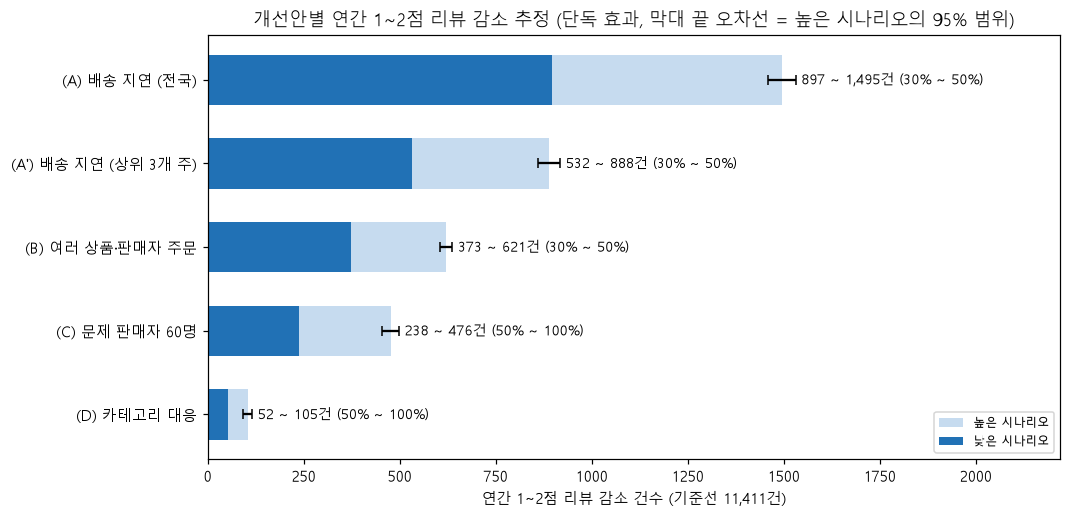

저장: reports/figures/q5_impact_feasibility.png


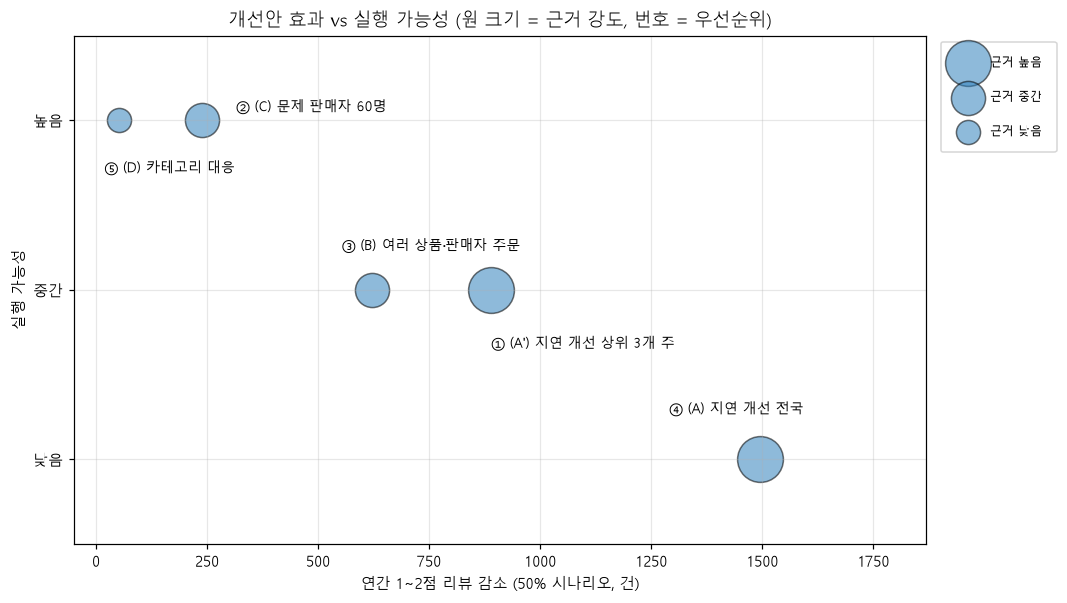

In [13]:
plot_rows = [("A", "(A) 배송 지연 (전국)"), ("A_top", f"(A') 배송 지연 (상위 3개 주)"), ("B", "(B) 여러 상품·판매자 주문"),
             ("C", "(C) 문제 판매자 60명"), ("D", "(D) 카테고리 대응")]
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(plot_rows))[::-1]
for yi, (k, label) in zip(y, plot_rows):
    lv_lo, lv_hi = interventions[k]["levels"]
    lo = single_eff[(single_eff["key"] == k) & (single_eff["level"] == lv_lo)].iloc[0]
    hi = single_eff[(single_eff["key"] == k) & (single_eff["level"] == lv_hi)].iloc[0]
    ax.barh(yi, hi["1~2점 감소(평균)"], color="#c6dbef", height=0.6, label="높은 시나리오" if k == "A" else None)
    ax.barh(yi, lo["1~2점 감소(평균)"], color="#2171b5", height=0.6, label="낮은 시나리오" if k == "A" else None)
    ax.errorbar(hi["1~2점 감소(평균)"], yi, xerr=[[hi["1~2점 감소(평균)"] - hi["범위 하한"]], [hi["범위 상한"] - hi["1~2점 감소(평균)"]]],
                fmt="none", color="black", capsize=3)
    ax.text(hi["범위 상한"] + 15, yi, f"{lo['1~2점 감소(평균)']:,.0f} ~ {hi['1~2점 감소(평균)']:,.0f}건 ({lv_lo:.0%} ~ {lv_hi:.0%})", va="center", fontsize=9)
ax.set_yticks(y, [r[1] for r in plot_rows])
ax.set_xlabel(f"연간 1~2점 리뷰 감소 건수 (기준선 {TOTAL_LOW:,}건)")
ax.set_title("개선안별 연간 1~2점 리뷰 감소 추정 (단독 효과, 막대 끝 오차선 = 높은 시나리오의 95% 범위)")
ax.set_xlim(0, single_eff["범위 상한"].max() * 1.45)
ax.legend(loc="lower right", fontsize=8)
save(fig, "q5_low_score_reduction.png")
plt.show()

feas = {"높음": 3, "중간": 2, "낮음": 1}
short = {"A_top": "① (A') 지연 개선 상위 3개 주", "C": "② (C) 문제 판매자 60명", "B": "③ (B) 여러 상품·판매자 주문",
         "A": "④ (A) 지연 개선 전국", "D": "⑤ (D) 카테고리 대응"}
offsets = {"A_top": (0, -38), "C": (22, 6), "B": (-20, 26), "A": (-60, 30), "D": (-10, -34)}  # 라벨이 겹치지 않게 개선안별 위치 지정
fig, ax = plt.subplots(figsize=(10, 6))
for _, r in priority.iterrows():
    size = {"높음": 900, "중간": 500, "낮음": 250}[r["근거 강도"]]
    x_, y_ = r["연간 1~2점 감소 (50%)"], feas[r["실행 가능성"]]
    ax.scatter(x_, y_, s=size, alpha=0.55, color="#3182bd", edgecolor="black")
    ax.annotate(short[r["key"]], (x_, y_), xytext=offsets[r["key"]], textcoords="offset points", fontsize=9, ha="left")
for s, lab in [(900, "근거 높음"), (500, "근거 중간"), (250, "근거 낮음")]:
    ax.scatter([], [], s=s, alpha=0.55, color="#3182bd", edgecolor="black", label=lab)
ax.set_yticks([1, 2, 3], ["낮음", "중간", "높음"])
ax.set_ylim(0.5, 3.5)
ax.set_xlim(-50, priority["연간 1~2점 감소 (50%)"].max() * 1.25)
ax.set_xlabel("연간 1~2점 리뷰 감소 (50% 시나리오, 건)")
ax.set_ylabel("실행 가능성")
ax.set_title("개선안 효과 vs 실행 가능성 (원 크기 = 근거 강도, 번호 = 우선순위)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), labelspacing=1.8, borderpad=1.2, fontsize=8)
ax.grid(alpha=0.3)
save(fig, "q5_impact_feasibility.png")
plt.show()

## 정리

경영진 요약, 개선안별 근거와 가정, 우선순위와 이유, 해석 주의점은 `reports/analysis/q5_recommendations.md`에 정리했다.